# 02 - Personas: choosing the number of clusters
**K-means** groups members who behave alike. We must tell it how many groups (k). Two tools help:
* **Elbow** (inertia): how tight the groups are. More groups always means tighter groups, so we look for where the improvement flattens.
* **Silhouette**: how well separated the groups are (-1 to 1, higher is better).

In [1]:
import sys, json, warnings; sys.path.insert(0, ".."); warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.db import get_engine
from src.part2_pipeline import load_raw
from src.features import clean_metrics, compute_features
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25,
                     "figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 11})
BLUE, ORANGE, GREY = "#2f6db5", "#d9822b", "#8a8f98"
members, metrics, engagement = load_raw(get_engine())
truth = pd.read_csv("../data/synthetic_ground_truth.csv")
from src.part3_ml import fit_personas, PERSONA_FEATURES, K_ALLOWED
get_ipython().run_line_magic('matplotlib', 'inline')  # part3_ml uses a no-display backend; show charts here
mc, _ = clean_metrics(metrics)
feats = compute_features(members, mc, engagement, 90)
personas, profile, scores, k, desc, Xs, labels = fit_personas(feats)
display(scores.round(3))

,k,inertia,silhouette
0,2,2853.848,0.335
1,3,2340.509,0.292
2,4,1949.015,0.242
3,5,1736.278,0.243
4,6,1559.628,0.258
5,7,1408.669,0.263
6,8,1304.143,0.275


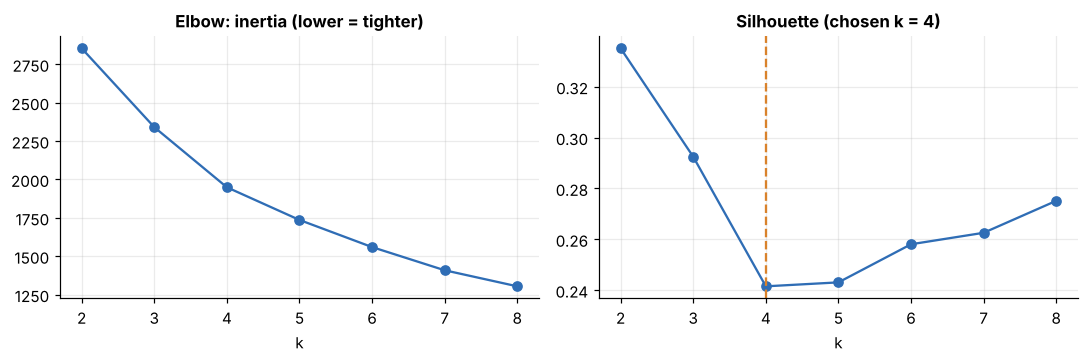

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].plot(scores.k, scores.inertia, marker="o", color=BLUE); ax[0].set_title("Elbow: inertia (lower = tighter)"); ax[0].set_xlabel("k")
ax[1].plot(scores.k, scores.silhouette, marker="o", color=BLUE); ax[1].axvline(k, ls="--", color=ORANGE); ax[1].set_title(f"Silhouette (chosen k = {k})"); ax[1].set_xlabel("k")
plt.tight_layout()

### How we chose k (honestly)
* There is **no sharp elbow** and silhouette scores are modest (about 0.24-0.34). Real people form a continuum, not neat islands. That is normal; we say so rather than pretend.
* k=2 and k=3 score best, but 2-3 personas are too coarse to act on (e.g. they hide the quiet users).
* Product rule: allow **k = 4 to 6**, then choose the **smallest k whose silhouette is within 0.02 of the best** (parsimony: fewer personas are easier to use). Result: **k = 4**.

## The personas

In [3]:
display(profile.round(1))
for p in json.load(open("../outputs/personas.json")): print(f"- {p['persona']} ({p['members']} members): {p['description']}")

,steps_30d,active_minutes_30d,sleep_hours_30d,consistency_score,app_opens_30d,app_opens_7d,content_views_30d,mood_avg_30d,persona,members
cluster,,,,,,,,,,
0,6875.9,29.7,7.1,63.3,2.2,2.2,29.9,3.4,Curious Desk-Sitters,155
1,6743.0,31.0,6.1,45.9,1.4,1.3,21.8,3.4,Irregular Rhythms,81
2,11749.7,60.7,7.3,60.3,3.7,3.7,62.2,3.8,Engaged Achievers,91
3,7442.7,36.2,7.3,62.5,0.4,0.3,2.2,3.4,Quiet Drifters,173


- Curious Desk-Sitters (155 members): Love the app and the content but move little - a good fit for easy, small activity goals.
- Irregular Rhythms (81 members): Unpredictable sleep and activity (typically shift workers) - offer flexible, routine-building tips.
- Engaged Achievers (91 members): Very active, open the app almost daily and love content - ideal for challenges and streaks.
- Quiet Drifters (173 members): Rarely open the app and are only moderately active - at highest risk of dropping off; need a simple hook.


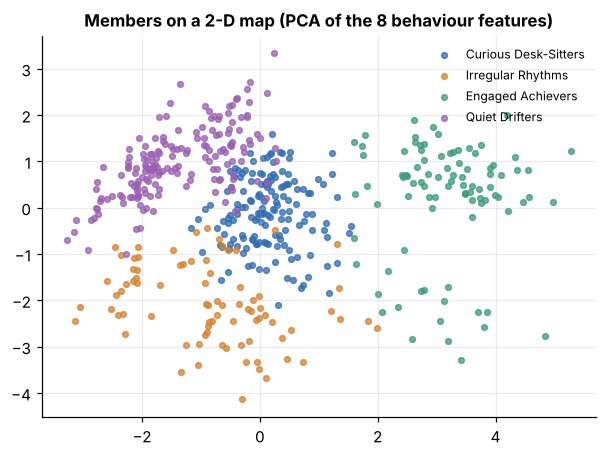

In [4]:
from sklearn.decomposition import PCA
pc = PCA(2, random_state=0).fit_transform(Xs)
fig, ax = plt.subplots(figsize=(6.5, 4.5))
pal = [BLUE, ORANGE, "#3a9d78", "#9a5fb4", GREY, "#c0463d"]
for c, name in profile["persona"].items(): ax.scatter(*pc[labels==c].T, s=14, color=pal[c], label=name, alpha=.75)
ax.set_title("Members on a 2-D map (PCA of the 8 behaviour features)"); ax.legend(frameon=False, fontsize=8)

## Sanity check against the hidden archetypes
The generator secretly created 5 habit types. The clusters should line up with them reasonably (never perfectly - people vary and the types overlap).


In [5]:
x = personas.merge(truth[["member_id","_archetype"]], on="member_id")
display(pd.crosstab(x["persona"], x["_archetype"]))
print("Job-type mix per persona:"); display(pd.crosstab(personas["persona"], members.set_index("member_id").loc[personas.member_id,"job_type"].values, normalize="index").round(2))

_archetype,achiever,dabbler,desk_curious,silent_mover,steady
persona,,,,,
Curious Desk-Sitters,3,0,63,0,89
Engaged Achievers,91,0,0,0,0
Irregular Rhythms,11,10,24,13,23
Quiet Drifters,19,45,15,61,33


Job-type mix per persona:


col_0,desk,field,shift
persona,,,
Curious Desk-Sitters,0.70,0.28,0.02
Engaged Achievers,0.58,0.21,0.21
Irregular Rhythms,0.00,0.01,0.99
Quiet Drifters,0.64,0.34,0.02
